# Epidemiology
*SIR epidemics fitted to case counts, and what the fits forecast*

A new disease spreads through a population; a health agency sees only the daily count of new cases. This page fits an SIR model to such counts, with a measure that lowers transmission part way through, for 400 data sets at once, and asks what the fits say about the weeks after the data end. One lane is one reported day of one data set, and the gradient that drives the fit comes from reverse mode.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, plot_style, show, to_numpy, xp
plot_style()

## The epidemic, once

Three groups, as fractions of a population of `POP = 1 000 000`: susceptible `S`, infectious `I` and recovered `R`. Time is in days.

- `dS/dt = -beta S I`, `dI/dt = beta S I - gamma I`, `dR/dt = gamma I`. `beta` is the transmission rate per day and `gamma = 0.2` per day is the recovery rate, so an infection lasts five days.
- `beta` takes one value `beta1` until day `T_SWITCH = 14` and another, `beta2`, after it: a measure that lowers contact. Their ratio to `gamma` are the reproduction numbers before and after, `R = beta / gamma`.
- The agency sees the new infections of each day, `rho` times the fall in `S` over that day, with `rho = 0.3` of them reported. The start is `I0 = 1e-4` of the population infectious.
- The model leaves out the latent period, age structure, reporting delays and births and deaths. `gamma`, `rho`, `I0` and the day of the measure are taken as known; the two transmission rates are what the data must tell.

Declare the words once as a `KernelKind`. One lane is one reported day of one data set: it needs the two rates and the day, and gives that day's new cases.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Mutable, Param, Scalar
from hawk.ext import DATA_ONLY, KernelKind


class Epidemic(KernelKind, slug="epidemic"):
    beta1: Scalar       # transmission rate before the measure (per day); one per lane, so a fit is one call
    beta2: Scalar       # transmission rate after it (per day)
    day: Scalar         # the reported day of this lane (1 = the first day)
    gamma: Param        # recovery rate (per day)
    i0: Param           # infectious fraction at day 0
    rho: Param          # reported share of the new infections
    t_switch: Param     # the day the measure starts
    guard = DATA_ONLY

Epidemic

__main__.Epidemic

## One reported day

The kernel integrates the three groups from day 0 to the end of its day with fixed-step classical Runge-Kutta (RK4), `per_day` steps a day, and writes the new cases of that day, `rho (S_start_of_day - S_end_of_day)`. The loop leaves when the lane's own day is done: `if k + 0.5 > per_day * day: break`. The rate switches from `beta1` to `beta2` at the first step after `t_switch`. The kernel also writes `S`, `R`, `R` at the switch and the sum `S + I + R`, for the checks below.

A lane integrates from day 0 again, so a data set of 35 days costs the work of about 18 days times 35 lanes; that is the price of one flat call for the whole ensemble, and it makes the derivative of every day one launch. The step count is part of the kernel, so a small function builds it.

In [4]:
PER_DAY, DAYS_MAX = 8, 120


def make_sir(per_day):
    steps = per_day * DAYS_MAX

    @Epidemic
    def sir(beta1, beta2, day, gamma, i0, rho, t_switch,
            cases: Mutable[Scalar], s_out: Mutable[Scalar], r_out: Mutable[Scalar], r_sw: Mutable[Scalar], total: Mutable[Scalar]):
        h = 1.0 / per_day
        s = 1.0 - i0
        i = i0
        r = 0.0
        s_prev = s
        r_sw = 0.0
        beta = beta1
        for k in range(steps):
            if k + 0.5 > per_day * day:                                  # this lane's day is done
                break
            if m.abs(k - per_day * (day - 1.0)) < 0.5:                   # the start of the lane's day
                s_prev = s
            if m.abs(k - per_day * t_switch) < 0.5:                      # the measure starts
                r_sw = r
            if k + 0.5 > per_day * t_switch:
                beta = beta2
            a1 = beta * s * i
            k1s = -a1
            k1i = a1 - gamma * i
            k1r = gamma * i
            s2 = s + 0.5 * h * k1s
            i2 = i + 0.5 * h * k1i
            a2 = beta * s2 * i2
            k2s = -a2
            k2i = a2 - gamma * i2
            k2r = gamma * i2
            s3 = s + 0.5 * h * k2s
            i3 = i + 0.5 * h * k2i
            a3 = beta * s3 * i3
            k3s = -a3
            k3i = a3 - gamma * i3
            k3r = gamma * i3
            s4 = s + h * k3s
            i4 = i + h * k3i
            a4 = beta * s4 * i4
            k4s = -a4
            k4i = a4 - gamma * i4
            k4r = gamma * i4
            s = s + h * (k1s + 2.0 * k2s + 2.0 * k3s + k4s) / 6.0
            i = i + h * (k1i + 2.0 * k2i + 2.0 * k3i + k4i) / 6.0
            r = r + h * (k1r + 2.0 * k2r + 2.0 * k3r + k4r) / 6.0
        cases = rho * (s_prev - s)
        s_out = s
        r_out = r
        total = s + i + r
    return sir


sir = make_sir(PER_DAY)
sir

<Kernel sir slots=12>

## A sweep of measures

How much does the strength of the measure matter? Take the population as it is, with `beta1 = 0.5` per day (`R = 2.5`), and let the measure bring `beta2` down to between 0.5 (no measure) and 0.15 (`R = 0.75`), eight values, each reported for 120 days: 960 lanes, one call. `eagle.deploy(sir).run(...)` takes the planes and parameters by name and returns the outputs by name.

In [5]:
POP, GAMMA, I0, RHO, T_SWITCH = 1_000_000, 0.2, 1e-4, 0.3, 14.0
B1_TRUE, B2_TRUE = 0.5, 0.26
OVERDISPERSION = 25.0                                         # variance = count + count^2 / 25: Poisson scatter plus about 20% reporting noise
FIXED = dict(gamma=GAMMA, i0=I0, rho=RHO, t_switch=T_SWITCH)
days_all = np.arange(1, DAYS_MAX + 1, dtype=float)
model = eagle.deploy(sir)

b2_values = np.linspace(0.5, 0.15, 8)
out = model.run(beta1=np.full(8 * DAYS_MAX, B1_TRUE), beta2=np.repeat(b2_values, DAYS_MAX), day=np.tile(days_all, 8), **FIXED)
daily = POP * np.asarray(out["cases"]).reshape(8, DAYS_MAX)
peak_day = daily.argmax(axis=1) + 1
print("beta2 (per day)  R after  peak day  peak cases/day  total cases in 120 days")
for b2, row, pk in zip(b2_values, daily, peak_day):
    print(f"{b2:15.3f}  {b2 / GAMMA:7.2f}  {pk:8d}  {row.max():14.0f}  {row.sum() / RHO:23.0f}")

beta2 (per day)  R after  peak day  peak cases/day  total cases in 120 days
          0.500     2.50        29           17585                   892559
          0.450     2.25        31           14033                   853579
          0.400     2.00        35           10580                   797469
          0.350     1.75        40            7242                   714369
          0.300     1.50        47            4148                   585734
          0.250     1.25        59            1579                   366003
          0.200     1.00        14             843                    95421
          0.150     0.75        14             843                    28907


## Check it against what is known

Three checks.

**An identity of the model, independent of the scheme.** For any transmission rate, `d ln S / dt = -beta I = -(beta / gamma) dR/dt`, so `ln(S0 / S(t)) = (1 / gamma) (integral of beta dR)`. With a rate that changes once, that is `(beta1 / gamma) R(t_switch) + (beta2 / gamma) (R(t) - R(t_switch))` for `t` after the switch. It uses nothing of how the kernel steps, so the gap between the two sides is the kernel's own error. Doubling the steps should divide it by about 16: RK4 is fourth order.

**Stability, against the Jacobian.** The Jacobian of the three groups has rows summing in size to at most `beta` and `beta + gamma`, so its eigenvalues are no larger than `beta + gamma`. The Jacobian has a positive eigenvalue while the epidemic grows, so this is an accuracy margin, not a decay rate: `h` times `beta + gamma` stays far inside RK4's stability region (edge 2.785). The check counts the steps against it.

**By construction.** `S + I + R` stays 1, because a Runge-Kutta step keeps any linear sum of the states exactly. It catches a sign or a factor wrong in a rate, not a bad scheme.

In [6]:
def identity_gap(program, b1=B1_TRUE, b2=B2_TRUE, day=56.0):
    # |ln(S0 / S) - the integral of beta dR / gamma| at `day`, the two sides of the identity of the model
    o = program.run(beta1=np.array([b1]), beta2=np.array([b2]), day=np.array([day]), **FIXED)
    S, R, Rsw = float(o["s_out"][0]), float(o["r_out"][0]), float(o["r_sw"][0])
    return abs(np.log((1 - I0) / S) - (b1 * Rsw + b2 * (R - Rsw)) / GAMMA)


gaps = [identity_gap(eagle.deploy(make_sir(n))) for n in (2, 4, 8)]
for n, g in zip((2, 4, 8), gaps):
    print(f"{n:>3} steps a day: gap in the identity {g:.1e}")
ratios = [gaps[0] / gaps[1], gaps[1] / gaps[2]]
assert all(10 < r < 24 for r in ratios), ratios
print(f"doubling the steps divides the gap by {ratios[0]:.1f} and {ratios[1]:.1f}: fourth order")

LIMIT = 2.785                                                  # RK4 on the negative real axis
fastest = B1_TRUE + GAMMA                                       # the largest |eigenvalue| of the Jacobian, per day
for n in (2, 4, 8):
    edge = fastest / n
    print(f"{n:>3} steps a day: h x (beta + gamma) = {edge:.3f} -> {'inside' if edge < LIMIT else 'outside'} RK4's region (edge {LIMIT})")
    assert edge < LIMIT

TOL_SUM = 1e-12
assert np.abs(np.asarray(out["total"]) - 1).max() < TOL_SUM
print(f"S + I + R = 1 over {out['total'].size} lanes, worst gap {np.abs(np.asarray(out['total']) - 1).max():.1e} (by construction)")

  2 steps a day: gap in the identity 5.5e-10
  4 steps a day: gap in the identity 3.6e-11
  8 steps a day: gap in the identity 2.3e-12
doubling the steps divides the gap by 15.2 and 15.6: fourth order
  2 steps a day: h x (beta + gamma) = 0.350 -> inside RK4's region (edge 2.785)
  4 steps a day: h x (beta + gamma) = 0.175 -> inside RK4's region (edge 2.785)
  8 steps a day: h x (beta + gamma) = 0.087 -> inside RK4's region (edge 2.785)
S + I + R = 1 over 960 lanes, worst gap 1.8e-15 (by construction)


## The gradient the fit needs

A fit needs the derivative of each day's cases with respect to the two transmission rates. `hawk.diff.vjp(sir, wrt=("beta1", "beta2"))` derives the reverse-mode kernel, and `eagle.deploy` takes the kernel and its derivative together. With a seed of one for `cases`, every lane returns its own derivative; with the residual as the seed, the sum over a data set's 35 lanes is the gradient of its misfit. Reverse mode costs one pass however many parameters there are, which is why it is the tool when a model grows more rates.

Three checks, at the true parameters, on all 35 days.
- **Exactness:** a central finite difference of the same integration, in float64, relative step 1e-6. It is the derivative of exactly what the kernel computes, so the tolerance is a rounding one.
- **Reference:** the sensitivity equations of the model, integrated separately in NumPy at 32 steps a day: the derivative of each group with respect to each rate, from `dy/dt = f` and `d(dy/dp)/dt = (df/dy)(dy/dp) + df/dp`. It shares neither the tape nor the step with the kernel, so it differs only by the kernel's scheme error.
- **Causality:** the days up to the measure cannot depend on `beta2`, so the kernel's `d cases / d beta2` must be exactly zero on days 1-14, and the check asserts it.

In [7]:
from hawk import Kernel
from hawk.diff import vjp

sir_vjp = Kernel("sir_vjp", vjp(sir, wrt=("beta1", "beta2")))
model, backward = eagle.deploy([sir, sir_vjp])
D_FIT = 35
days_fit = days_all[:D_FIT]


def curves_dev(b1, b2, days=days_fit, program=None):
    # model counts per day, one row per (beta1, beta2) pair; a device array when a GPU is there
    n = len(b1)
    o = (program or model).run(beta1=xp.repeat(xp.asarray(b1), len(days)), beta2=xp.repeat(xp.asarray(b2), len(days)),
                               day=xp.tile(xp.asarray(days), n), **FIXED)
    return POP * o["cases"].reshape(n, len(days))


def jacobian_dev(b1, b2, days=days_fit):
    # d counts / d beta1 and d beta2, one row per pair, one column per day; a device array when a GPU is there
    n, lanes = len(b1), len(b1) * len(days)
    o = backward.run(beta1=xp.repeat(xp.asarray(b1), len(days)), beta2=xp.repeat(xp.asarray(b2), len(days)), day=xp.tile(xp.asarray(days), n), **FIXED,
                     bar_cases=xp.ones(lanes), bar_s_out=xp.zeros(lanes), bar_r_out=xp.zeros(lanes), bar_r_sw=xp.zeros(lanes),
                     bar_total=xp.zeros(lanes))
    return POP * o["bar_beta1"].reshape(n, len(days)), POP * o["bar_beta2"].reshape(n, len(days))


def curves(*args, **kwargs):
    return to_numpy(curves_dev(*args, **kwargs))


def jacobian(*args, **kwargs):
    return tuple(to_numpy(a) for a in jacobian_dev(*args, **kwargs))


g1, g2 = jacobian(np.array([B1_TRUE]), np.array([B2_TRUE]))

rel = 1e-6                                                     # exactness: central differences of the integration
fd1 = (curves(np.array([B1_TRUE * (1 + rel)]), np.array([B2_TRUE])) - curves(np.array([B1_TRUE * (1 - rel)]), np.array([B2_TRUE]))) / (2 * rel * B1_TRUE)
fd2 = (curves(np.array([B1_TRUE]), np.array([B2_TRUE * (1 + rel)])) - curves(np.array([B1_TRUE]), np.array([B2_TRUE * (1 - rel)]))) / (2 * rel * B2_TRUE)
TOL_GRAD = 1e-6
gap = max(np.abs(g1 - fd1).max() / np.abs(g1).max(), np.abs(g2 - fd2).max() / np.abs(g2).max())
assert gap < TOL_GRAD, gap
print(f"derivative against central differences over {g1.size + g2.size} values: worst gap {gap:.1e} of the largest value < {TOL_GRAD:g}")


def sensitivities(b1, b2, per_day=32):
    # the model's own sensitivity equations: state (S, I, R) and d(state)/d(beta1), d(state)/d(beta2), RK4, daily S and its derivatives
    h = 1.0 / per_day
    y = np.array([1 - I0, I0, 0.0])
    z = np.zeros((2, 3))
    daily_s, daily_z = [y[0]], [z[:, 0].copy()]
    def rhs(y, z, beta, which):
        s, i = y[0], y[1]
        f = np.array([-beta * s * i, beta * s * i - GAMMA * i, GAMMA * i])
        dfdy = np.array([[-beta * i, -beta * s, 0.0], [beta * i, beta * s - GAMMA, 0.0], [0.0, GAMMA, 0.0]])
        dfdp = np.zeros((2, 3)); dfdp[which] = [-s * i, s * i, 0.0]
        return f, z @ dfdy.T + dfdp
    for k in range(per_day * D_FIT):
        beta, which = (b1, 0) if k < per_day * T_SWITCH else (b2, 1)
        f1, g1_ = rhs(y, z, beta, which)
        f2, g2_ = rhs(y + 0.5 * h * f1, z + 0.5 * h * g1_, beta, which)
        f3, g3_ = rhs(y + 0.5 * h * f2, z + 0.5 * h * g2_, beta, which)
        f4, g4_ = rhs(y + h * f3, z + h * g3_, beta, which)
        y = y + h * (f1 + 2 * f2 + 2 * f3 + f4) / 6
        z = z + h * (g1_ + 2 * g2_ + 2 * g3_ + g4_) / 6
        if (k + 1) % per_day == 0:
            daily_s.append(y[0]); daily_z.append(z[:, 0].copy())
    daily_z = np.array(daily_z)                                 # (day, parameter): d S / d beta
    return POP * RHO * (daily_z[:-1] - daily_z[1:]).T           # d cases / d beta, (parameter, day)


ref = sensitivities(B1_TRUE, B2_TRUE)
TOL_REF = 1e-4
gap_ref = max(np.abs(g1[0] - ref[0]).max() / np.abs(ref[0]).max(), np.abs(g2[0] - ref[1]).max() / np.abs(ref[1]).max())
assert gap_ref < TOL_REF, gap_ref
print(f"against the sensitivity equations: worst gap {gap_ref:.1e} of the largest value < {TOL_REF:g}")

before = days_fit <= T_SWITCH
assert (g2[0][before] == 0).all() and (g1[0] != 0).all()
print(f"beta2 has no effect before day {T_SWITCH:g}: its derivative is exactly zero on those {before.sum()} days")

derivative against central differences over 70 values: worst gap 6.5e-09 of the largest value < 1e-06


against the sensitivity equations: worst gap 1.4e-07 of the largest value < 0.0001
beta2 has no effect before day 14: its derivative is exactly zero on those 14 days


## Fit 400 data sets at once

Draw 400 data sets from the true rates, `beta1 = 0.5` and `beta2 = 0.26`: each day's count is the clean one plus Gaussian noise whose variance is `count + count^2 / 25`, the scatter of counts plus about 20% of reporting noise. The weights `1 / sd` use the true counts and are taken as known. Fit each set's two rates by minimising `L = (1/2) sum ((model - data) / sd)^2`, whose minimum is the maximum-likelihood fit for that noise.

The method is Levenberg-Marquardt in `ln beta1` and `ln beta2`, as on the [Biochemistry](15_biochemistry) page. Per iteration: the residuals from `curves`, the 35 x 2 matrix `J` from one reverse-mode launch over all `400 x 35` lanes, and a hawk kernel with one lane per data set that takes the 35 x 2 matrix `J` and the 35 residuals and returns the damped Gauss-Newton step `-(J^T J + mu I)^-1 J^T r` with `m.lm_step`. A step that lowers the misfit is accepted and `mu` shrinks; one that does not is refused and `mu` grows. Start every set from `beta1 = beta2 = 0.35`.

In [8]:
from hawk import Matrix, Vector


@hawk.kernel
def lm_kernel(J: Matrix[35, 2], r: Vector[35], mu: Scalar, step: Mutable[Vector[2]]):
    step = m.lm_step(J, r, mu)                                    # -(J^T J + mu I)^-1 J^T r, one lane per data set


lm_solver = eagle.deploy(lm_kernel)


def fit(data, sd, iterations=60, start=(0.35, 0.35), trail=None):
    # maximum-likelihood beta1, beta2 for each row of `data` (data sets x days), by Levenberg-Marquardt in log-parameters
    data, sd = xp.asarray(data), xp.asarray(sd)
    n = data.shape[0]
    theta = xp.log(xp.asarray(start))[:, None] * xp.ones((2, n))
    mu = xp.full(n, 1e-2)

    def residual_of(theta):
        return (curves_dev(*xp.exp(theta)) - data) / sd

    def normal_equations(theta):
        b1, b2 = xp.exp(theta)
        j1, j2 = jacobian_dev(b1, b2)
        J = xp.stack([j1 * b1[:, None], j2 * b2[:, None]], axis=2) / sd[:, :, None]      # d residual / d ln beta: data sets x days x 2
        return J, xp.swapaxes(J, 1, 2) @ J

    r = residual_of(theta)
    misfit = 0.5 * (r**2).sum(axis=1)
    used = 0
    if trail is not None:
        trail.append(to_numpy(theta))
    for used in range(1, iterations + 1):
        J, A = normal_equations(theta)
        step = lm_solver.run(J=xp.ascontiguousarray(J.reshape(n, -1).T), r=xp.ascontiguousarray(r.T), mu=mu)     # components first: (70, n), (35, n)
        trial = theta + step
        r_trial = residual_of(trial)
        misfit_trial = 0.5 * (r_trial**2).sum(axis=1)
        accept = misfit_trial < misfit
        theta = xp.where(accept, trial, theta)
        r = xp.where(accept[:, None], r_trial, r)
        misfit = xp.where(accept, misfit_trial, misfit)
        mu = xp.where(accept, xp.maximum(mu * 0.3, 1e-12), mu * 3.0)
        if trail is not None:
            trail.append(to_numpy(theta))
        if float(xp.abs(step).max()) < 1e-9:
            break
    J, A = normal_equations(theta)                                                      # J^T J at each fit: its own covariance
    return to_numpy(theta), to_numpy(misfit), to_numpy(A), used


rng = np.random.default_rng(3)
N = 400
clean = curves(np.array([B1_TRUE]), np.array([B2_TRUE]))[0]
sd = np.sqrt(clean + clean**2 / OVERDISPERSION)[None, :] * np.ones((N, 1))
data = clean + sd * rng.normal(size=(N, D_FIT))
trail = []
theta, misfit, fisher_fit, used = fit(data, sd, trail=trail)
b1_fit, b2_fit = np.exp(theta)
print(f"{N} data sets fitted in {used} Levenberg-Marquardt iterations")
print(f"beta1: mean {b1_fit.mean():.4f} (true {B1_TRUE}), spread {b1_fit.std():.4f};  beta2: mean {b2_fit.mean():.4f} (true {B2_TRUE}), spread {b2_fit.std():.4f}")

400 data sets fitted in 35 Levenberg-Marquardt iterations
beta1: mean 0.5000 (true 0.5), spread 0.0047;  beta2: mean 0.2600 (true 0.26), spread 0.0047


## Does the fit recover the truth, within its stated uncertainty?

For noise of known size the uncertainty of a maximum-likelihood fit is its Fisher covariance, `(J^T J)^-1`, with `J` the derivatives of the weighted counts. Four checks:
- the spread of the 400 fitted values matches the covariance at the true rates, within 15%;
- the mean fitted value is within four standard errors of the mean of the truth;
- the misfit `2 L` follows a chi-squared law with `35 - 2` degrees of freedom, so its mean is 33;
- the true rates fall inside each data set's own 95% region (the covariance at the fit itself) for about 95% of the data sets. The region is a linearised one, so a little under 95% is expected in a curved model; the check allows 90 to 99%.

In [9]:
jb1, jb2 = (a[0] for a in jacobian(np.array([B1_TRUE]), np.array([B2_TRUE])))
J = np.stack([jb1 * B1_TRUE, jb2 * B2_TRUE], axis=1) / sd[0][:, None]      # d weighted count / d (ln beta1, ln beta2), 35 x 2
cov = np.linalg.inv(J.T @ J)
se = np.sqrt(np.diag(cov))
err = theta - np.log([[B1_TRUE], [B2_TRUE]])
spread = err.std(axis=1)
assert (np.abs(spread / se - 1) < 0.15).all(), (spread, se)
print(f"spread of ln beta1, ln beta2: fitted {spread.round(4)} against predicted {se.round(4)}")

mean_err = err.mean(axis=1)
assert (np.abs(mean_err) < 4 * se / np.sqrt(N)).all(), mean_err
print(f"mean error {mean_err.round(4)} within four standard errors of the mean ({(4 * se / np.sqrt(N)).round(4)})")

chi2 = 2 * misfit
assert abs(chi2.mean() - (D_FIT - 2)) < 4 * np.sqrt(2 * (D_FIT - 2) / N), chi2.mean()
print(f"mean chi-squared {chi2.mean():.2f} against {D_FIT - 2} degrees of freedom")

inside = np.einsum("in,nij,jn->n", err, fisher_fit, err) <= 5.99
assert 0.90 < inside.mean() < 0.99, inside.mean()
print(f"the true rates lie inside the 95% region of {inside.mean() * 100:.1f}% of the data sets (95% expected, binomial +-{100 * np.sqrt(0.95 * 0.05 / N):.1f}%)")

R_before, R_after = b1_fit / GAMMA, b2_fit / GAMMA
print(f"reproduction number: before the measure {R_before.mean():.2f} +- {R_before.std():.2f} (true {B1_TRUE / GAMMA:.2f}), "
      f"after {R_after.mean():.2f} +- {R_after.std():.2f} (true {B2_TRUE / GAMMA:.2f})")

spread of ln beta1, ln beta2: fitted [0.0093 0.018 ] against predicted [0.0095 0.0185]
mean error [-0.0001 -0.    ] within four standard errors of the mean ([0.0019 0.0037])
mean chi-squared 32.91 against 33 degrees of freedom
the true rates lie inside the 95% region of 94.2% of the data sets (95% expected, binomial +-1.1%)
reproduction number: before the measure 2.50 +- 0.02 (true 2.50), after 1.30 +- 0.02 (true 1.30)


## What do the fits forecast?

Every fit is a full epidemic, so each can be run past the last day of data. Take the 400 fitted rate pairs and report days 36 to 120. The true curve is known here, so the check is whether the forecasts bracket it: the median of the forecast total cases over those days must be within 10% of the truth, and the true total must lie between the 2.5th and 97.5th percentiles of the fits.

In [10]:
days_future = days_all[D_FIT:]
future = curves(b1_fit, b2_fit, days=days_all)                      # (fit, 120 days): counts per day
truth_full = curves(np.array([B1_TRUE]), np.array([B2_TRUE]), days=days_all)[0]
total_fit = future[:, D_FIT:].sum(axis=1)
total_true = truth_full[D_FIT:].sum()
lo, med, hi = np.percentile(total_fit, [2.5, 50, 97.5])
assert abs(med / total_true - 1) < 0.10 and lo < total_true < hi, (lo, med, hi, total_true)
print(f"reported cases over days 36-120: truth {total_true:,.0f}; fits: median {med:,.0f}, 95% range {lo:,.0f} to {hi:,.0f}")
peak_fit = future.argmax(axis=1) + 1
print(f"peak day: truth {truth_full.argmax() + 1}, fits {np.percentile(peak_fit, 2.5):.0f} to {np.percentile(peak_fit, 97.5):.0f}")

reported cases over days 36-120: truth 104,302; fits: median 104,565, 95% range 90,740 to 115,949
peak day: truth 57, fits 55 to 58


## The picture

Left: one data set. The dots are its 35 daily counts, the line the fit, and the dashed line the true curve; the fit goes on past the last day, as a forecast. The thin lines are 60 of the 400 fits, run to day 120: the fan that opens after the data end is the uncertainty of the forecast. Right: the fitted `beta1` and `beta2` of all 400 data sets, with the true value as a cross and the 95% region predicted from the Fisher covariance as the ellipse.


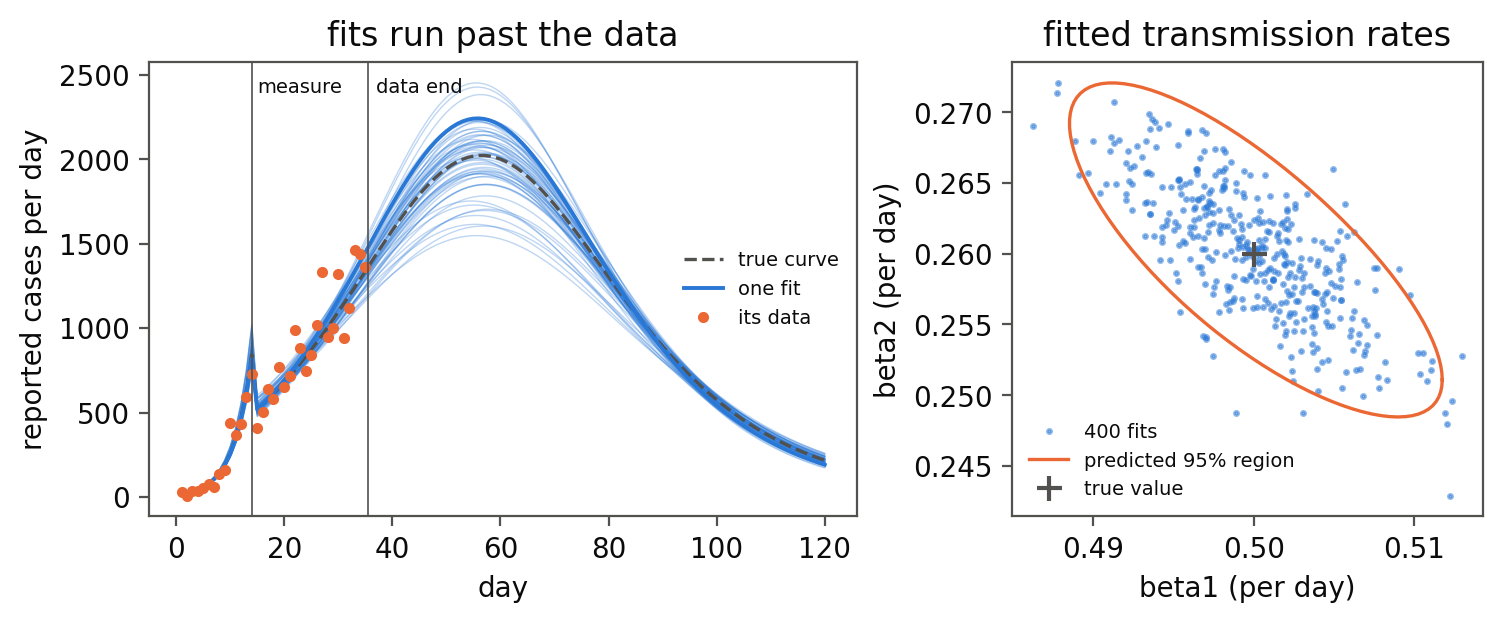
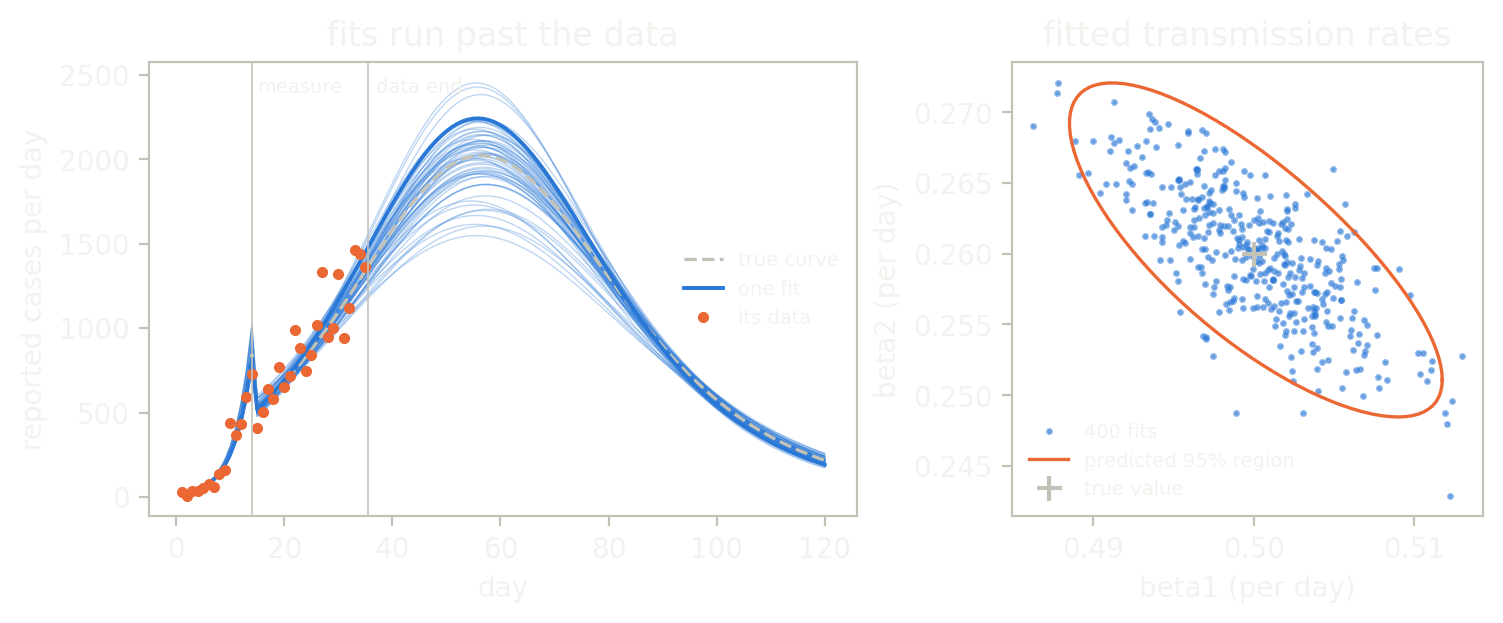

In [11]:
import matplotlib.pyplot as plt

colours = ["#2a78d6", "#eb6834"]
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True, gridspec_kw={"width_ratios": [1.5, 1]})
for k in range(60):
    left.plot(days_all, future[k], lw=0.5, color=colours[0], alpha=0.3)
left.plot(days_all, truth_full, "--", lw=1.2, color="#898781", label="true curve")
left.plot(days_all, future[0], lw=1.4, color=colours[0], label="one fit")
left.plot(days_fit, data[0], "o", ms=3, color=colours[1], label="its data")
left.axvline(T_SWITCH, color="#898781", lw=0.6); left.axvline(D_FIT + 0.5, color="#898781", lw=0.6)
left.text(T_SWITCH + 1, left.get_ylim()[1] * 0.93, "measure", fontsize=7, color="#898781")
left.text(D_FIT + 2, left.get_ylim()[1] * 0.93, "data end", fontsize=7, color="#898781")
left.set_xlabel("day"); left.set_ylabel("reported cases per day"); left.set_title("fits run past the data"); left.legend(frameon=False, fontsize=7, loc="center right")

right.plot(b1_fit, b2_fit, ".", ms=3, alpha=0.5, color=colours[0], label="400 fits")
angle = np.linspace(0, 2 * np.pi, 100)
ring = np.exp(np.log([[B1_TRUE], [B2_TRUE]]) + np.linalg.cholesky(cov) @ np.stack([np.cos(angle), np.sin(angle)]) * np.sqrt(5.99))
right.plot(*ring, lw=1.2, color=colours[1], label="predicted 95% region")
right.plot([B1_TRUE], [B2_TRUE], "+", ms=9, mew=1.5, color="#898781", label="true value")
right.set_xlabel("beta1 (per day)"); right.set_ylabel("beta2 (per day)"); right.set_title("fitted transmission rates"); right.legend(frameon=False, fontsize=7)
show(fig, f"Two panels. Left: reported cases per day against day, reaching a peak of about {truth_full.max():,.0f} near day {truth_full.argmax() + 1}, with the growth slowing after the measure at day {T_SWITCH:g}; {D_FIT} noisy daily counts, one fit and the dashed true curve agree, and 60 thin fitted curves continue past day {D_FIT} in a fan whose total over days {D_FIT + 1} to 120 has a 95 percent range of {lo:,.0f} to {hi:,.0f} against a true {total_true:,.0f}. Right: fitted beta1 from {b1_fit.min():.2f} to {b1_fit.max():.2f} and beta2 from {b2_fit.min():.2f} to {b2_fit.max():.2f} for {N} data sets, inside the predicted 95 percent ellipse around the true values {B1_TRUE:g} and {B2_TRUE:g}.")

## A bigger fit, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same `fit` keeps every array on the device (CuPy) and brings back only the fitted values; it runs on a larger ensemble of data sets, 4 000, drawn the same way. The spread of the fitted values must again match the Fisher prediction, within 10%.

In [12]:
if gpu_available():
    big = 4_000
    big_sd = np.sqrt(clean + clean**2 / OVERDISPERSION)[None, :] * np.ones((big, 1))
    big_data = clean + big_sd * np.random.default_rng(11).normal(size=(big, D_FIT))
    probe = curves_dev(np.array([B1_TRUE]), np.array([B2_TRUE]))
    assert type(probe).__module__.startswith("cupy"), "the result is a device array: the kernel ran on the GPU"
    big_theta, _, _, _ = fit(big_data, big_sd)
    big_err = big_theta - np.log([[B1_TRUE], [B2_TRUE]])
    assert (np.abs(big_err.std(axis=1) / se - 1) < 0.10).all(), (big_err.std(axis=1), se)
    print(f"{big} data sets fitted: spread {big_err.std(axis=1).round(4)} against predicted {se.round(4)}")
else:
    print("no GPU here; the fit stays at", N, "data sets")

no GPU here; the fit stays at 400 data sets


## The animation

The same fits, drawn as the days pass. Each thin line is one of 80 fitted epidemics, growing day by day; the dots are the observed counts of one data set, which stop at day 35. After that the lines are forecasts, and they spread. The helper that writes a looping GIF for a light page and one for a dark page is shared with the other domain pages.

In [13]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

SHOWN = 80
top = 1.08 * max(future[:SHOWN].max(), truth_full.max())


def render(theme, t):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(5.0, 2.9), facecolor=pal["bg"])
    ax = fig.add_axes([0.14, 0.17, 0.82, 0.76], facecolor=pal["bg"])
    ax.axvline(T_SWITCH, color=pal["sub"], lw=0.6); ax.axvline(D_FIT + 0.5, color=pal["sub"], lw=0.6)
    ax.text(T_SWITCH + 1, top * 0.93, "measure", fontsize=6.5, color=pal["sub"]); ax.text(D_FIT + 2, top * 0.93, "data end", fontsize=6.5, color=pal["sub"])
    for k in range(SHOWN):
        ax.plot(days_all[:t], future[k, :t], lw=0.5, color="#2a78d6", alpha=0.45)
    ax.plot(days_all[:t], truth_full[:t], "--", lw=1.0, color=pal["ink"])
    shown_days = min(t, D_FIT)
    ax.plot(days_fit[:shown_days], data[0, :shown_days], "o", ms=2.6, color="#eb6834")
    ax.set_xlim(0, DAYS_MAX); ax.set_ylim(0, top)
    ax.set_xlabel("day", color=pal["sub"], fontsize=8); ax.set_ylabel("reported cases per day", color=pal["sub"], fontsize=8)
    ax.tick_params(colors=pal["sub"], labelsize=7)
    for sp in ax.spines.values():
        sp.set_color(pal["rule"])
    ax.text(0.98, 0.9, "data" if t <= D_FIT else "forecast", transform=ax.transAxes, ha="right", fontsize=8, color=pal["ink"])
    return frame_of(fig, pal["bg"])


frames_at = list(range(2, DAYS_MAX + 1, 2)) + [DAYS_MAX] * 8
sizes = {}
for theme in ("light", "dark"):
    sizes.update(write_anim([render(theme, t) for t in frames_at], f"epidemic_fits_{theme}", fps=12))
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")
assert max(sizes.values()) < 1.5e6

epidemic_fits_light.gif 552 kB
epidemic_fits_dark.gif 542 kB


```{image} ../../_static/anim/epidemic_fits_light.gif
:class: only-light
:alt: Reported cases per day against day. Eighty fitted epidemic curves grow together up to day 35, where the data end, along a dashed true curve with orange data dots; after the measure at day 14 the rise slows, and past day 35 the curves fan out as forecasts around the true curve.
```
```{image} ../../_static/anim/epidemic_fits_dark.gif
:class: only-dark
:alt: Reported cases per day against day. Eighty fitted epidemic curves grow together up to day 35, where the data end, along a dashed true curve with orange data dots; after the measure at day 14 the rise slows, and past day 35 the curves fan out as forecasts around the true curve.
```

## What just happened

- `Epidemic` named the two rates, the day and the fixed constants once; `sir` is the integration in those names, one lane per reported day, leaving its loop when its day is done.
- The identity `ln(S0 / S) = (1 / gamma) integral of beta dR`, which does not depend on the scheme, held to a gap that fell about sixteen-fold per halving of the step; the stability limit was checked against the Jacobian's bound, and `S + I + R = 1` held by construction.
- `vjp` gave every day's derivative in one launch; it matched a finite difference of the same integration to rounding and the model's own sensitivity equations within the scheme's error.
- Levenberg-Marquardt fitted 400 data sets, with the damped Gauss-Newton step taken by `m.lm_step` in a hawk kernel. The spread matched the Fisher covariance, the misfit had the right mean, and the forecasts bracketed the true total.

## Try this

Move the measure later (`T_SWITCH`) or give it less effect, and watch the second rate become harder to pin down: the Fisher covariance says by how much before you run a fit. Or let the reporting fraction `rho` be unknown too, a third column in `J`, and see what the counts alone can and cannot say about it.

## Next

[Biochemistry](15_biochemistry) fits a rate law the same way, with one rate law and one gradient. [Control](21_control) runs one plant under many gains and stops each lane when it has settled.